# Did the molecule really split in two? Count the peaks in a carbon spectrum

You'll check the notebook 01 peptides again, this time through their carbon atoms, and count the
large carbonyl peaks before and after. This notebook goes with the NMR project Extra of the same name.

Hydrogen NMR (1H) shows the hydrogens; carbon NMR (13C) shows the carbon skeleton. In these carbon
spectra, read which peaks are there, not their size. They were recorded fast, with about one second
between scans. A carbon with no hydrogens attached, such as a carbonyl (C=O), recovers slowly
between scans and comes out weak.

Time: about 30 minutes. Same samples as notebook 01, in 98% acid. Boxes headed **RECORD YOUR
ANSWER** are where you write something; you compare with the paper at the end.

Data: Petkowski, M. D. Seager, Bains and S. Seager, Zenodo [10.5281/zenodo.11223995](https://doi.org/10.5281/zenodo.11223995), CC BY 4.0. Paper: *Scientific Reports* 14, 17083 (2024).

In [1]:
# Setup. In Colab this first installs the training package and the Rakiura helper (about 30 seconds).
import importlib.util, os
if importlib.util.find_spec("nmrtrain") is None:
    %pip install -q "nmrtrain @ git+https://github.com/Rakiura-Inc/morning-star-nmr@main"
if importlib.util.find_spec("rakiura") is None:
    %pip install -q "rakiura @ git+https://github.com/Rakiura-Inc/rakiura-py@main"
import matplotlib.pyplot as plt
import nmrtrain as nt

NOTEBOOK = "notebooks/05_read_a_13c_series.ipynb"
MODE = nt.portal.connect(NOTEBOOK)

Not connected to Rakiura. Your work stays on this computer. Run the Connect cell below to tick steps on Rakiura.


> **CONNECT TO RAKIURA (optional, recommended)**
>
> **What it does:** ticks your checklist on the step as you go and attaches your figures to it. Nothing is sent until you connect.
>
> **How:** run the cell below, open the link it prints, check the code matches the one printed here, and click Allow. In Colab you do this once per session. To skip the click, add your key as a Colab secret named `RAKIURA_KEY` (the key icon on the left; get the key in Rakiura under Settings > Notebook key).
>
> **Skipping it is fine:** your work is kept on this computer, and you can attach your files on the step page instead.

In [2]:
# Connect to Rakiura (optional). Open the link it prints, check the code matches, click Allow.
MODE = nt.portal.connect(NOTEBOOK, sign_in=True)

Not connected to Rakiura. Your work stays on this computer. Run this cell again to try once more, or attach your files on the step page.


### What you need

Ala-Ala has three kinds of carbon, two of each (one per alanine), coloured in the drawing below:

- the carbonyls (C=O): one in the peptide bond, one in the carboxylic acid group (COOH) at the end
  of the chain
- the alpha carbons: the backbone carbons next to the nitrogen
- the methyl carbons (CH3)

Typical positions in carbon NMR:

| Carbon | Typical position |
|---|---|
| carbonyl (C=O) | near 170 to 180 ppm |
| carbon bonded to nitrogen | about 30 to 65 ppm |
| methyl carbon | about 10 to 30 ppm |

A carbon bonded to oxygen or nitrogen sits at higher ppm than one bonded only to carbon and
hydrogen.

Longer version: NMR project Extra, Did the molecule really split in two? Count the peaks in a carbon spectrum.

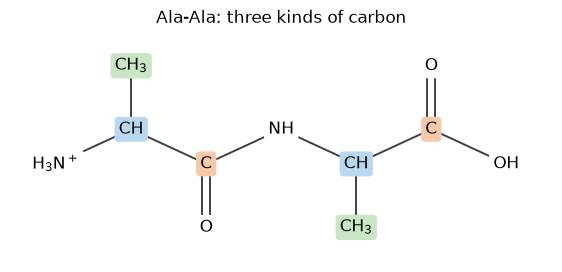

In [3]:
# Ala-Ala's carbons by kind: orange carbonyls (C=O), blue alpha carbons, green methyl carbons.
fig, ax = plt.subplots(figsize=(7, 3.2))
nt.plot.draw_dipeptide(ax, "Ala", "Ala-Ala: three kinds of carbon",
                       {"C1": ("", "#f6c9a8"), "C2": ("", "#f6c9a8"), "A1": ("", "#b9d7f0"), "A2": ("", "#b9d7f0"),
                        "S1": ("", "#c8e6c3"), "S2": ("", "#c8e6c3")})
plt.show()

> **RECORD YOUR ANSWER: predict where each kind of carbon appears**
>
> **What gets saved:** `MY_PREDICTION`, three positions in ppm, saved with the time.
>
> **Where to look:** the drawing and the table of typical positions above.
>
> **How to fill this in:**
> - `carbonyl_ppm`: the carbonyls (C=O), a number in ppm like `100`
> - `alpha_ppm`: the alpha carbons
> - `methyl_ppm`: Ala-Ala's methyl carbons
> - The cell after it says where these kinds of carbon typically sit; you then find the real positions in the stack.

<details><summary>Stuck? Open hint 1</summary>

Start with the carbonyl: the table gives its region.

</details>

<details><summary>Stuck? Open hint 2</summary>

The more oxygen or nitrogen on or next to a carbon, the higher its ppm: the carbonyl highest,
the alpha carbon (bonded to nitrogen) next, the methyl lowest.

</details>

In [4]:
MY_PREDICTION = {
    "carbonyl_ppm": ...,   # a number in ppm: the C=O carbons
    "alpha_ppm": ...,      # a number in ppm: the backbone carbons next to the nitrogen
    "methyl_ppm": ...,     # a number in ppm: Ala-Ala's CH3 carbons
}
nt.record.predict("c13", MY_PREDICTION)

Fill in at least one prediction above (replace the ...), then run this cell again.


In [5]:
# Reveal: runs only after you predicted. It checks your reasoning, not this dataset.
if nt.record.revealed("c13"):
    c13_key = nt.answers.load("c13_series", quiet=True)
    nt.checks.check_prediction(MY_PREDICTION, c13_key["prediction"]).show("Your predictions")

Make your prediction in the cell above first.


## Load and stack

AA 13C 98% w/w D2SO4: 5 spectra, all cached
Data: Petkowski, J. J.; Seager, M. D.; Bains, W.; Seager, S. (2024). General Instability of Dipeptides in Concentrated Sulfuric Acid as Relevant for the Venus Cloud Habitability (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.11223995 (CC BY 4.0). Paper: Petkowski et al. 2024, Scientific Reports 14, 17083, doi:10.1038/s41598-024-67342-w.
GG 13C 98% w/w D2SO4: 5 spectra, all cached
Data: Petkowski, J. J.; Seager, M. D.; Bains, W.; Seager, S. (2024). General Instability of Dipeptides in Concentrated Sulfuric Acid as Relevant for the Venus Cloud Habitability (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.11223995 (CC BY 4.0). Paper: Petkowski et al. 2024, Scientific Reports 14, 17083, doi:10.1038/s41598-024-67342-w.
Checks on Ala-Ala in 98% acid: 6 passed, 0 flagged
  nothing to flag
Checks on Gly-Gly in 98% acid: 6 passed, 0 flagged
  nothing to flag


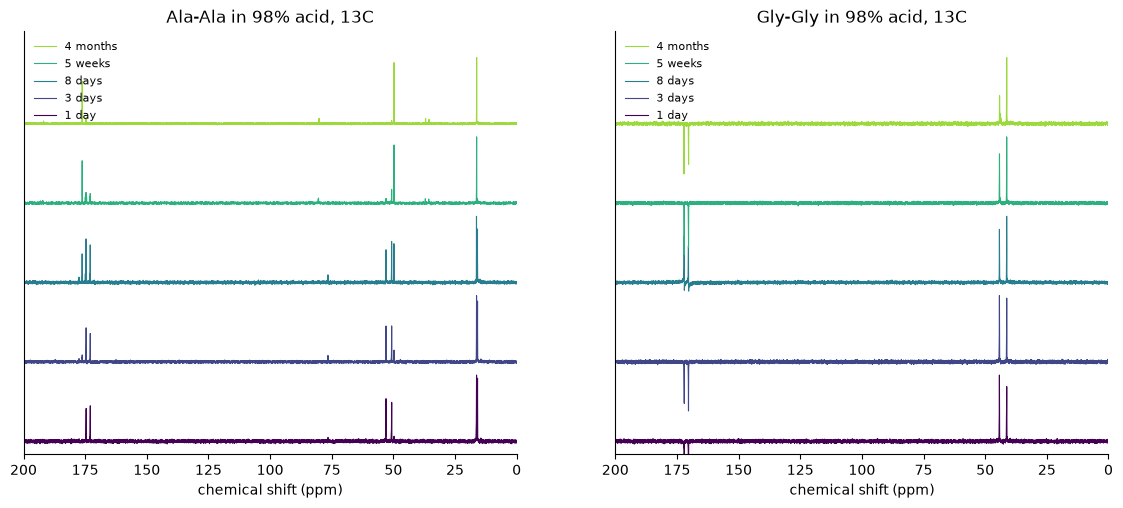

In [6]:
c13 = {pep: nt.load_series("11223995", pep, acid="K", nucleus="13C") for pep in ("AA", "GG")}
fig_13c, axes = plt.subplots(1, 2, figsize=(14, 5.5))
traps = {}
for ax, (pep, ser) in zip(axes, c13.items()):
    nt.plot.stack(ser, 0, 200, norm=(5, 200), ax=ax, title=f"{nt.io.NAMES[pep]} in 98% acid, 13C")
    traps[pep] = nt.checks.run_traps(ser)
plt.show()

### Trap: missing carbonyls

Look at Gly-Gly near 170 ppm: its carbonyls show in only one spectrum. In these fast carbon runs a
carbonyl peak can be missing from a whole spectrum, so do not count a carbonyl as gone just because
it is missing. Use the spectra where the carbonyls do show: count the large ones at each time point,
and check whether each sits where it did at 1 day.

In [7]:
for s in c13["GG"]:
    seen = [p["ppm"] for p in nt.peaks.pick(s, 160, 185, 0.05, group_ppm=0.5, ref=(5, 200))]
    print(f"Gly-Gly {s.time_label:9s} carbonyl peaks: {seen or 'none seen'}")

Gly-Gly 1 day     carbonyl peaks: none seen
Gly-Gly 3 days    carbonyl peaks: none seen
Gly-Gly 8 days    carbonyl peaks: [172.116, 170.348]
Gly-Gly 5 weeks   carbonyl peaks: none seen
Gly-Gly 4 months  carbonyl peaks: none seen


## Compare first and last

The next cell lists the peaks in the first and last spectrum of each peptide, and which are at
both times, at the first only, and at the last only. `MIN_HEIGHT` sets the smallest peak it lists.

In [8]:
MIN_HEIGHT = 0.05
my_peaks, changes = {}, {}
for pep, ser in c13.items():
    my_peaks[pep] = {s.time: nt.peaks.pick(s, 5, 200, MIN_HEIGHT, group_ppm=0.5) for s in (ser[0], ser[-1])}
    for t, pk in my_peaks[pep].items():
        print(nt.io.NAMES[pep], f"{t:7s}", [round(p["ppm"], 1) for p in pk])
    changes[pep] = {k: [round(p, 1) for p in v] for k, v in nt.peaks.compare(*my_peaks[pep].values(), tol=0.5).items()}
    c = {k: ", ".join(f"{p:.1f}" for p in v) or "none" for k, v in changes[pep].items()}
    print(f"   at both times {c['kept']} | first only {c['lost']} | last only {c['new']}")

Ala-Ala 1day    [174.6, 172.9, 76.5, 53.0, 50.7, 49.8, 16.1]
Ala-Ala 4Month  [176.2, 174.6, 80.1, 49.8, 36.9, 35.6, 16.2]
   at both times 174.6, 49.8, 16.1 | first only 172.9, 76.5, 53.0, 50.7 | last only 176.2, 80.1, 36.9, 35.6
Gly-Gly 1day    [44.2, 41.3]
Gly-Gly 4Month  [44.1, 41.3]
   at both times 44.2, 41.3 | first only none | last only none


### What you need

Read Ala-Ala's first (1 day) list. Each number is one carbon peak's position in ppm. Use the
table in the first box to say which peak is which kind of carbon.

Longer version: NMR project Extra, Did the molecule really split in two? Count the peaks in a carbon spectrum.

> **RECORD YOUR ANSWER: where do Ala-Ala's carbons really sit?**
>
> **What gets saved:** `MY_READING`, three positions in ppm, read off Ala-Ala's 1 day list.
>
> **Where to look:** the Ala-Ala 1 day list printed above, and the left stack.
>
> **How to fill this in:**
> - `carbonyl_ppm`: one of the carbonyl peaks, a number like `100.0`
> - `alpha_ppm`: one of the alpha carbon peaks
> - `methyl_ppm`: the methyl carbon peak
> - The check after it compares your reading with the ranges in this data and with your prediction.

<details><summary>Stuck? Open hint 1</summary>

Sort the 1 day list into three groups using the table of typical positions.

</details>

<details><summary>Stuck? Open hint 2</summary>

The highest values are carbonyls. The values between about 40 and 55 are alpha carbons. The
lowest value is the methyl. Leave out anything that fits none of the three.

</details>

In [9]:
MY_READING = {
    "carbonyl_ppm": ...,   # a number in ppm, from Ala-Ala's 1 day list
    "alpha_ppm": ...,      # a number in ppm
    "methyl_ppm": ...,     # a number in ppm
}
reading_key = nt.answers.load("c13_series", quiet=True)["reading"]
nt.checks.check_reading(MY_READING, reading_key, MY_PREDICTION).show("Where Ala-Ala's carbons sit at 1 day");

Where Ala-Ala's carbons sit at 1 day
  To do: Ala-Ala carbonyls at 1 day: read its position off the plot or peak list above and write it as a number.
  To do: Ala-Ala alpha carbons at 1 day: read its position off the plot or peak list above and write it as a number.
  To do: Ala-Ala methyl carbon at 1 day: read its position off the plot or peak list above and write it as a number.


### A filled example: Gly-Gly

Gly-Gly, filled in with the reasons. It shows the format; you do Ala-Ala below.

In [10]:
GG_EXAMPLE = {
    "call": "survives",        # its carbon peaks stay in place, as its hydrogen signals did in notebook 01
    "lost_ppm": [],            # nothing gone (its carbonyls show in only one spectrum: not evidence they are gone)
    "new_ppm": [],             # nothing new
    "kept_ppm": [44.2, 41.3],  # the two CH2 carbons, one per glycine
    "confidence": "medium",    # carbon supports the hydrogen decision; these fast 13C runs miss weak peaks
}

### What you need

- **Lost:** a peak at 1 day that is gone at the last time point.
- **New:** a peak at the last time point that was not there at 1 day. If Ala-Ala breaks down, expect
  many small new peaks: in 98% acid it releases acrylic acid, which keeps reacting into many products.
- **Kept:** a peak at both times.
- Peak heights in these carbon spectra do not measure amounts, so read which peaks are there, not
  their size.

Longer version: NMR project Extra, Did the molecule really split in two? Count the peaks in a carbon spectrum.

> **RECORD YOUR ANSWER: what changed in Ala-Ala's carbon spectrum?**
>
> **What gets saved:** `AA_LOST_PPM`, `AA_NEW_PPM` and `AA_KEPT_PPM`, three lists of 13C positions in ppm.
>
> **Where to look:** the Ala-Ala lists printed under Compare first and last, and the left stack.
>
> **How to fill this in:**
> - `AA_LOST_PPM`: peaks there at 1 day and gone at the last time point, as numbers like `[12.3, 45.6]`
> - `AA_NEW_PPM`: peaks at the last time point that were not there at 1 day
> - `AA_KEPT_PPM`: peaks there at both times
> - Leave a list as `[]` if there were none. Gly-Gly's record above shows the format.

<details><summary>Stuck? Open hint 1</summary>

Go peak by peak through the 1 day list: is there still a peak within about half a ppm at the last time point?

</details>

<details><summary>Stuck? Open hint 2</summary>

Count the carbonyls first: at 1 day there are two large ones. How many large ones are there at the
last time point, and does each sit where a 1 day one did?

</details>

In [11]:
AA_LOST_PPM = []    # peaks there at 1 day and gone at the last time point, like [12.3, 45.6]
AA_NEW_PPM = []     # peaks at the last time point that were not there at 1 day
AA_KEPT_PPM = []    # peaks there at both times

nt.record.write_down("AA_LOST_PPM", AA_LOST_PPM, "Ala-Ala (13C)", "lost_ppm", suggestion=changes["AA"]["lost"])
nt.record.write_down("AA_NEW_PPM", AA_NEW_PPM, "Ala-Ala (13C)", "new_ppm", suggestion=changes["AA"]["new"])
nt.record.write_down("AA_KEPT_PPM", AA_KEPT_PPM, "Ala-Ala (13C)", "kept_ppm", suggestion=changes["AA"]["kept"]);

**Saved** `AA_LOST_PPM = []`: no lost peaks for Ala-Ala (13C). If there were none, that is your answer and you can move on. The peak picker listed these as lost: 172.9, 76.5, 53 and 50.7. Copy the ones you agree with.

**Saved** `AA_NEW_PPM = []`: no new peaks for Ala-Ala (13C). If there were none, that is your answer and you can move on. The peak picker listed these as new: 176.2, 80.1, 36.9 and 35.6. Copy the ones you agree with.

**Saved** `AA_KEPT_PPM = []`: no kept peaks for Ala-Ala (13C). If there were none, that is your answer and you can move on. The peak picker listed these as kept: 174.6, 49.8 and 16.1. Copy the ones you agree with.

> **RECORD YOUR ANSWER: your decision on Ala-Ala from its carbons**
>
> **What gets saved:** `AA_CALL`, `AA_CONFIDENCE` and `AA_NOTE`, three short answers in quotes.
>
> **Where to look:** the lost, new and kept peaks you saved above.
>
> **How to fill this in:**
> - `AA_CALL`: your decision, one of these:
>   - `"survives"`: every large peak stays where it was at 1 day
>   - `"breaks down"`: large peaks vanish or a new large one appears at another position, with many small new peaks
>   - `"unsure"`: the data do not settle it; say why in `AA_NOTE`
> - `AA_CONFIDENCE`: how sure you are: `"low"`, `"medium"` or `"high"`
> - `AA_NOTE`: how many large carbonyl peaks you count at 1 day and at 4 months, and what that says about how Ala-Ala broke apart

<details><summary>Stuck? Open hint 1</summary>

Count the large carbonyl peaks at 1 day and at 4 months, and compare their positions.

</details>

<details><summary>Stuck? Open hint 2</summary>

Ala-Ala's two carbonyls sit in the peptide bond and in the COOH at the end. In 98% acid the end
alanine can be cut off at its nitrogen: the first alanine then leaves as alaninamide, whose one
carbonyl sits in its new amide group (CONH2), and the end alanine's carbons spread over many small
peaks. So two large carbonyls at 1 day and one large one at a new position later point to breakdown.

</details>

In [12]:
AA_CALL = ""          # your decision: "survives", "breaks down" or "unsure"
AA_CONFIDENCE = ""    # "low", "medium" or "high"
AA_NOTE = ""          # the large carbonyl peaks you count at 1 day and at 4 months, and what that says

nt.record.write_down("AA_CALL", AA_CALL, "Ala-Ala (13C)", "call")
nt.record.write_down("AA_CONFIDENCE", AA_CONFIDENCE, "Ala-Ala (13C)", "confidence")
nt.record.write_down("AA_NOTE", AA_NOTE, "Ala-Ala (13C)", "note");

**Not saved yet** `AA_CALL = ''`: write your decision for Ala-Ala (13C): one of "survives", "breaks down", "side chain changed" or "unsure" ("unsure" is a fair answer).

**Not saved yet** `AA_CONFIDENCE = ''`: write the confidence for Ala-Ala (13C): one of "low", "medium" or "high".

**Saved** `AA_NOTE = ''`: no note for Ala-Ala (13C). That is fine.

### Your verdict

Your verdict is everything you recorded about Ala-Ala's carbons, in one table: your decision, the
peaks behind it, how sure you are and your note. To change it, edit a line above and run this cell
again. The Gly-Gly row is the filled example.

In [13]:
MY_VERDICT = nt.record.build_verdict(
    {"AA": {"call": AA_CALL, "lost_ppm": AA_LOST_PPM, "new_ppm": AA_NEW_PPM, "kept_ppm": AA_KEPT_PPM,
            "confidence": AA_CONFIDENCE, "note": AA_NOTE}},
    names={"AA": "Ala-Ala (13C)"}, examples={"Gly-Gly (13C, example)": GG_EXAMPLE})["AA"]

| | decision | lost peaks (ppm) | new peaks (ppm) | kept peaks (ppm) | confidence | note |
|---|---|---|---|---|---|---|
| **Gly-Gly (13C, example)** | survives | none | none | 44.2, 41.3 | medium | (empty) |
| **Ala-Ala (13C)** | (empty) | none | none | none | (empty) | (empty) |

  Ala-Ala (13C): still empty: decision, lost peaks, new peaks, kept peaks, confidence. An empty peak list is fine if there were none, and "unsure" is a fair answer.
Nothing here blocks your hand-in. Change any answer above and run the cells again to update it.


The next cell compares your decision with the published finding (Petkowski et al. 2024, *Scientific
Reports* 14, 17083). If it differs, look again at the carbonyls; your hand-in goes to review as you
wrote it.

In [14]:
feedback = nt.checks.Report()
if nt.record.revealed("c13"):
    key = nt.answers.load("c13_series")
    c = nt.answers.case(key, "AA")
    feedback = nt.checks.check_verdict(MY_VERDICT, c).show("Your Ala-Ala verdict")

Make your prediction in the cell above first.


## Hand-in

> **SAVE YOUR HAND-IN: your carbon hand-in**
>
> **What gets saved:** in `handin/`: your 13C stacks and `verdict.json` (your verdict table and the feedback).
>
> **Where to look:** nothing new to fill in: the cell uses what you recorded above.
>
> **How to fill this in:**
> - Run the cell. These files are your hand-in for the NMR project Extra, Did the molecule really split in two? The stacks are your image of the carbon spectra, and `verdict.json` holds your note.
> - Nothing is sent for review until you run `nt.portal.submit()` in the last line of the cell.

<details><summary>Stuck? Open hint 1</summary>

If the figure is missing from the list it prints, run the stack cell, then this cell again.

</details>

<details><summary>Stuck? Open hint 2</summary>

If it says a name is not defined, run the notebook from the top (Runtime > Run all in Colab).

</details>

In [15]:
record = nt.record.handin("c13-verdict", figures={"stack_13C": fig_13c},
                          verdict={"verdict": MY_VERDICT, "reading": MY_READING, "feedback": [str(f) for f in feedback]},
                          numbers={"AA_call_13C": MY_VERDICT["call"] or "blank"},
                          question="c13", traps=nt.checks.traps_flagged(*traps.values()))
# nt.portal.submit()

Hand-in saved (offline mode: kept on this computer).
Saved for your hand-in:
   handin/c13-verdict/stack_13C.png
   handin/c13-verdict/verdict.json
Offline mode: attach these files on your step page. When you are connected to Rakiura, they are added for you.
